In [379]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_func as Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_plotting as Treat_acoustic_plotting
importlib.reload(Treat_acoustic_plotting)
from Treat_acoustic_plotting import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [380]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Sapphire\Q factor - radiative\2025-11'

Shapes = ['cylinder', 'round corner',  'round']
Shapes = ['cylinder',  'round']
Colors = {}



save_data = 0 #To save figures and results

Colors['cylinder'], Colors['round corner'], Colors['round'] = ['black', 'blue', 'green']
Spectra_data = {}

for shape in Shapes :

    dir_spectra= dir_root + r'\\' + shape
    Fname_list = ['size_sweep_AR_1.5_8 - with volume change']
    n_parameters=2
    Spectra_data[shape]= get_raw_size_sweep_data_Nathan(dir_spectra, Fname_list, verbose=True)

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.



Total size of raw data : 4620
----------- Find spectra size -----------
idx start : 0
value start : (3.924230331229131+2.8025785026896384j)
end index : 69
value end : (46.66803796469786+2.7544955723817988j)
----------- Find spectra size -----------
idx start : 70
value start : (3.9242462363230812+2.802567091428784j)
end index : 139
value end : (44.720408415015584+2.7587565156824065j)
----------- Find spectra size -----------
idx start : 140
value start : (3.9242631600945037+2.8025549661238056j)
end index : 209
value end : (42.85887548591499+2.7257658911729576j)
----------- Find spectra size -----------
idx start : 210
value start : (3.924281094292113+2.8025421277383225j)
end index : 279
value end : (41.10164529881752+2.664792012707445j)
----------- Find spectra size -----------
idx start : 280
value start : (3.924300045091536+2.802528579583j)
end index : 349
value end : (39.45626170979674+2.586522981612446j)
----------- Find spectra size -----------
idx start : 350
value start : (3.924

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



In [381]:
#plot_all_raw_spectra_interactive(Spectra_cylinder)

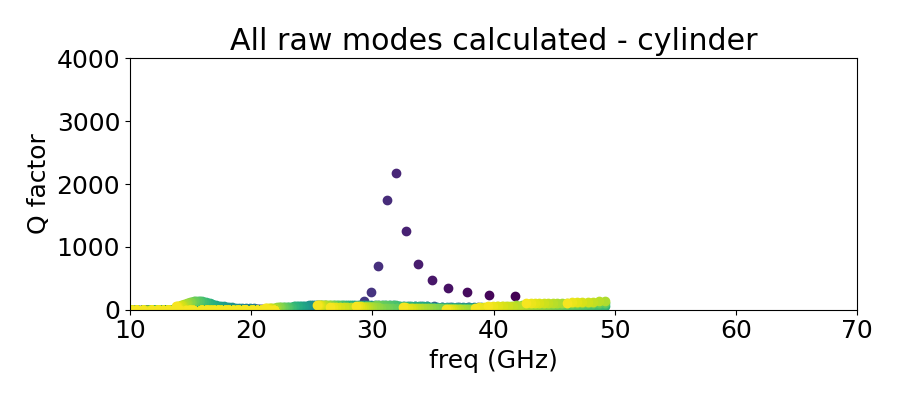

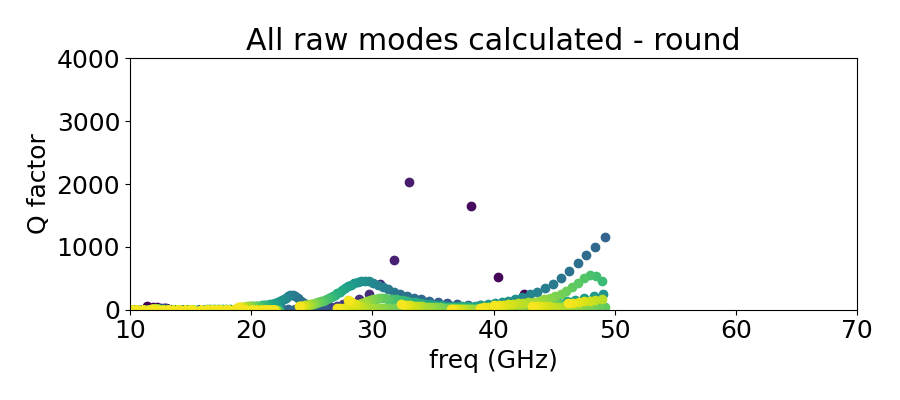

In [382]:
bottom = 0
top=4000
xlim = (10, 70)

for key in Spectra_data :
    spectra = Spectra_data[key]

    fig, ax = plt.subplots(figsize = (9,4))

    plot_all_raw_spectra(spectra, ax, plotted_key = 'Q')

    ax.set_xlabel('freq (GHz)')
    ax.set_ylabel('Q factor')
    ax.set_ylim(bottom=bottom )
    ax.set_ylim( top=top)
    ax.set_xlim(xlim)
    ax.set_title('All raw modes calculated - ' + key)
    #plt.legend(fontsize=10)
    plt.tight_layout()





In [383]:
for key in Spectra_data :
    spectra = Spectra_data[key]
    get_modes_with_Q_selection(spectra, Q_th=1)

## def freq limit functions to extract Q factor

In [384]:
Modes_dic = {}
Modes_dic['cylinder'] = {}
Modes_dic['round corner'] = {}
Modes_dic['round'] = {}


Boundary_func = {}

## For cylinder

def f1_low(ar) :
    return(38/(ar**0.5))

def f1_high(ar) :
    return(60/(ar**0.48))


Modes_dic['cylinder']['AR_crossing'] = 2.84
Modes_dic['cylinder']['Crossing'] = True


## For round corner

def f2_low(ar) :
    return(35/(ar**0.5))

def f2_high(ar) :
    return(60/(ar**0.48))

Modes_dic['round corner']['AR_crossing'] = 2.84
Modes_dic['round corner']['Crossing'] = True


## For round
def f3_low(ar) :
    return(38/(ar**0.5))

def f3_high(ar) :
    return(60/(ar**0.5))

Modes_dic['round']['AR_crossing'] = 3.41
Modes_dic['round']['Crossing'] = True


Boundary_func['cylinder'] = (f1_low, f1_high)
Boundary_func['round corner'] = (f2_low, f2_high)
Boundary_func['round'] = (f3_low, f3_high)


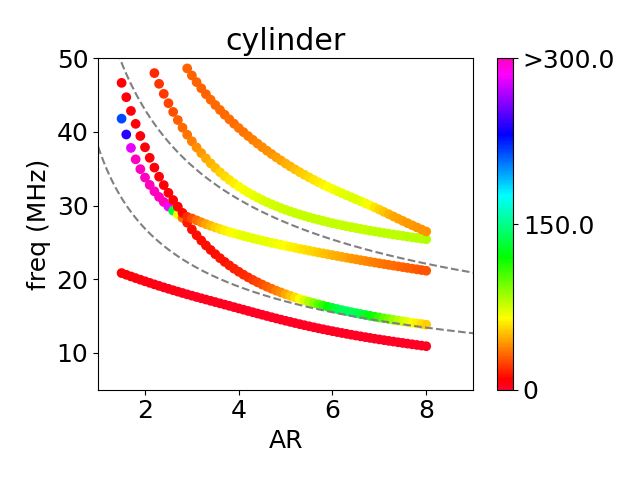

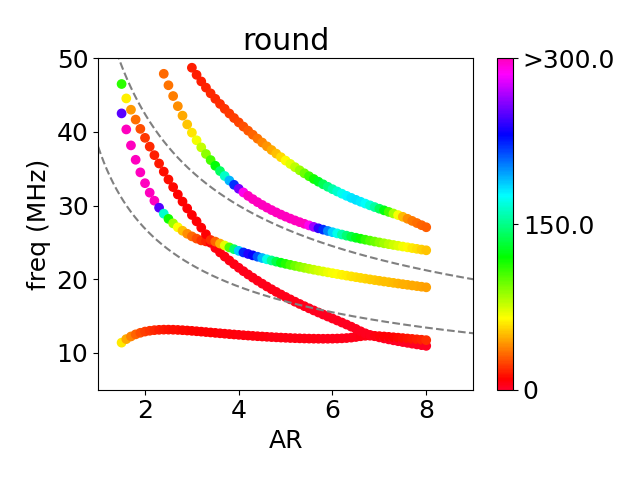

In [385]:
Q_max = 300
xlim = (1, 9)
ylim = (5, 50)
AR_array = np.linspace(1, 12, 1000)


for key in Spectra_data :
    spectra = Spectra_data[key]
   


    fig, ax = plt.subplots()
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    plt.xlabel('AR')
    plt.ylabel('freq (MHz)')
    plt.title(key)
    


    plot_all_acoustic_modes(spectra, ax, Q_max = Q_max, n_modes = 5)
    plt.tight_layout()
    

    dir_to_save = dir_root + r'\\' + key + r'\Figures'
    if not(os.path.exists(dir_to_save)) :
        os.mkdir(dir_to_save)
    os.chdir(dir_to_save)

    if save_data :
        plt.savefig('freq(AR).pdf')
        plt.savefig('freq(AR).png')



    ax.plot(AR_array, Boundary_func[key][0](AR_array), linestyle='--', color='grey')
    ax.plot(AR_array, Boundary_func[key][1](AR_array), linestyle='--', color='grey')



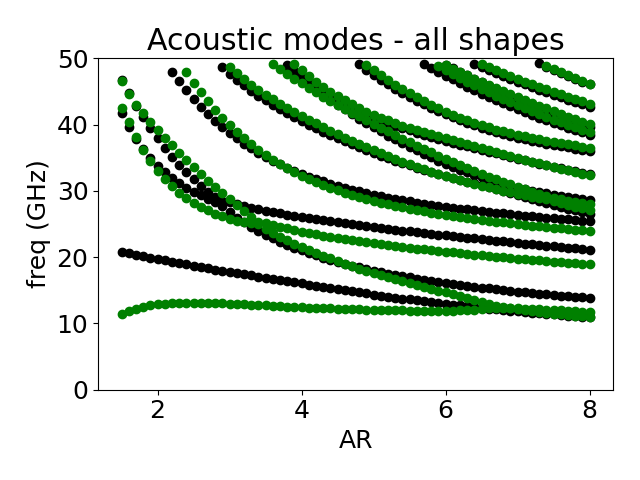

In [386]:
fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    


    for kkey in spectra :
        single_ND_modes = spectra[kkey]
        #print(np.sum(spectra['projection']))
        #print(spectra['eigen_freq'][np.argmax(spectra['projection'])])
        ax.scatter(single_ND_modes['AR']*np.ones(np.size(single_ND_modes['modes']['f'])), single_ND_modes['modes']['f'], color=Colors[key])

plt.title('Acoustic modes - all shapes')
plt.ylim(top=50, bottom=0)
plt.xlabel('AR')
plt.ylabel('freq (GHz)')
plt.tight_layout()

dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
if save_data :
    plt.savefig('freq(AR) - all shapes.pdf')
    plt.savefig('freq(AR) - all shapes.png')



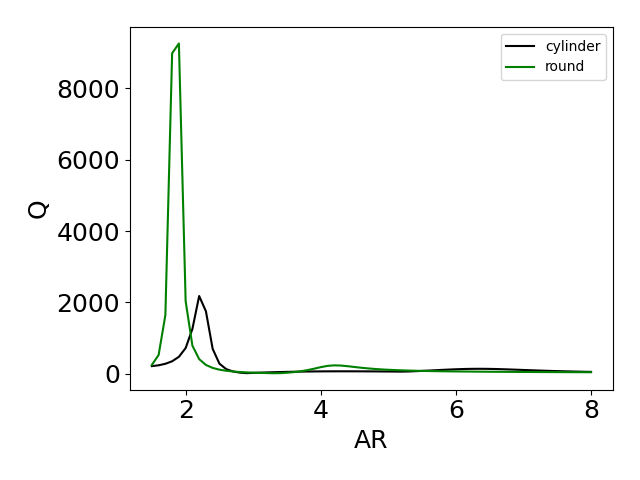

In [387]:
AR_min = 1
AR_max = 12

fig, ax = plt.subplots()



for key in Spectra_data :
    spectra = Spectra_data[key]
    AR, Q = get_max_Q(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],AR_min=AR_min, AR_max=AR_max)
    ax.plot(AR, Q, color=Colors[key], label = key)


plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()




## Get specific geometry modes

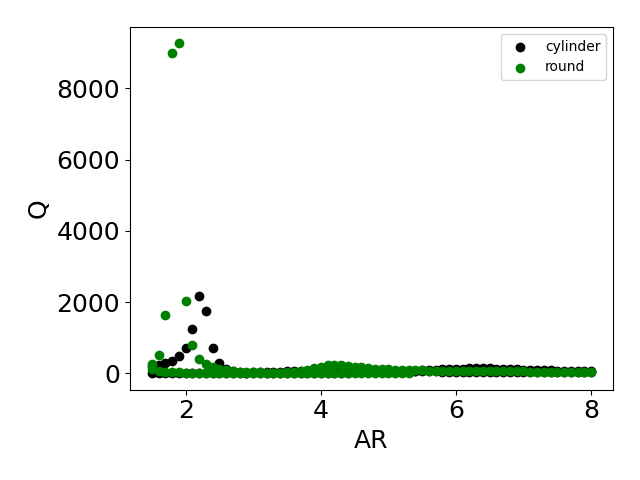

In [388]:
AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}
dV_all_shapes = {}
V_all_shapes = {}


fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]

    mode_dic = Modes_dic[key]
    AR_all_shapes[key],  Freq_all_shapes[key], Q_all_shapes[key], dV_all_shapes[key], V_all_shapes[key] = get_Q_specific_bands(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1], AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR_all_shapes[key],  Q_all_shapes[key], color=Colors[key], label = key)

plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
if save_data :
    plt.savefig('Q(AR) - all shapes.pdf')
    plt.savefig('Q(AR) - all shapes.png')

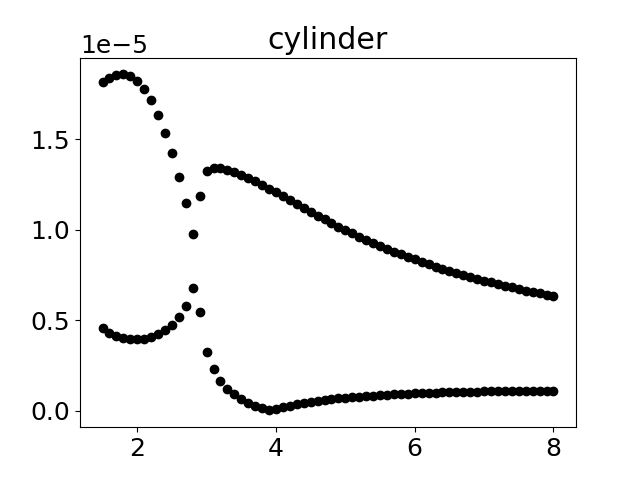

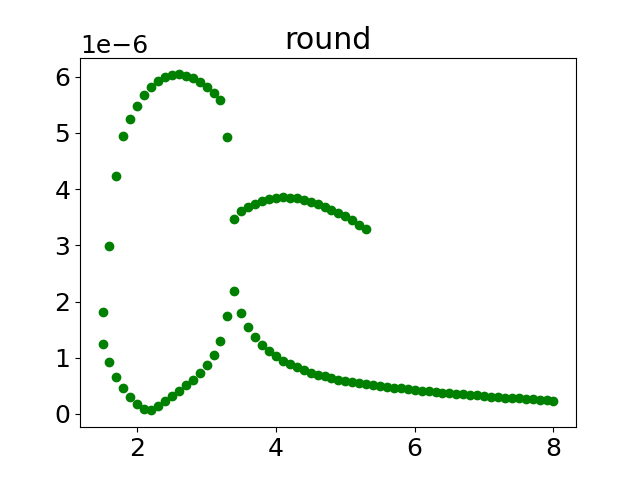

In [389]:
for key in Spectra_data :
    fig, ax = plt.subplots()
    spectra = Spectra_data[key]
    ax.scatter(AR_all_shapes[key],  dV_all_shapes[key]/V_all_shapes[key], color=Colors[key], label = key)
    ax.set_title(key)


## Save data

In [390]:
if save_data :
    for key in Spectra_data :
        spectra = Spectra_data[key]


        dir_to_save = dir_root + r'\\' + key + r'\Treated data'
        save_Q_with_AR_to_csv(dir_to_save, 'Selected acoustic modes', Q_all_shapes[key], AR_all_shapes[key], Freq_all_shapes[key])
        save_freq_with_AR_to_csv(dir_to_save, 'Q and freq', spectra)
